# Лабораторная работа № 4

Выполняли Свешников Борис и Хасанов Дмитрий.

## Условие

На самостоятельно выбранном датасете требуется:

1. выбрать количественный атрибут, предположить закон его распределения и проверить гипотезу как минимум двумя стат тестами, один из которых реализовать (явно указать нулевую и альтернативную гипотезы, вывести статистику критерия, критическую область и p-value)
2. разбить количественный атрибут на подвыборки по категориальному признаку и проверить их однородность как минимум двумя стат тестами, один из которых реализовать;
3. выбрать пару признаков, для которых предполагается связь, и проверить её как минимум двумя стат тестами.

## Анимешный датасет

Используется [Anime Recommendations Database](https://www.kaggle.com/datasets/CooperUnion/anime-recommendations-database), файл `anime.csv` содержит 12 294 тайтла с MyAnimeList и следующие поля:

| Поле | Смысл |
|---|---|
| `anime_id` | идентификатор аниме |
| `name` | название |
| `genre` | список жанров |
| `type` | TV, Movie, OVA, Special, ONA или Music |
| `episodes` | число эпизодов |
| `rating` | средняя пользовательская оценка из 10 |
| `members` | число участников сообщества аниме |

В рамках задания выбрали:

1. **закон распределения:** `rating`, гипотеза о нормальном законе
2. **однородность:** `rating` в группах `TV` и `Movie`
3. **связь:** `rating` и `members`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import Image, Markdown, display

from plots.lab4 import (
    association_plot,
    homogeneity_plot,
    normality_plot,
    overview_plot,
)
from utils.stat_tests import (
    jarque_bera_manual,
    ks_2samp_manual,
    pearson_permutation_test,
)

ALPHA = 0.05
SEED = 24422442
PERMUTATIONS = 5_000
DATA_PATH = Path("data/anime.csv")
OUTPUT_DIR = Path("images/anime")

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")

## Первичный анализ и подготовка данных

In [2]:
anime = pd.read_csv(DATA_PATH)
print(f"Размер исходной таблицы: {anime.shape[0]} строк × {anime.shape[1]} столбцов")
display(anime.head())

quality = pd.DataFrame({
    "dtype": anime.dtypes.astype(str),
    "missing": anime.isna().sum(),
    "unique": anime.nunique(dropna=True),
})
display(quality)

Размер исходной таблицы: 12294 строк × 7 столбцов


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


,dtype,missing,unique
anime_id,int64,0,12294
name,str,0,12292
genre,str,62,3264
type,str,25,6
episodes,str,0,187
rating,float64,230,598
members,int64,0,6706


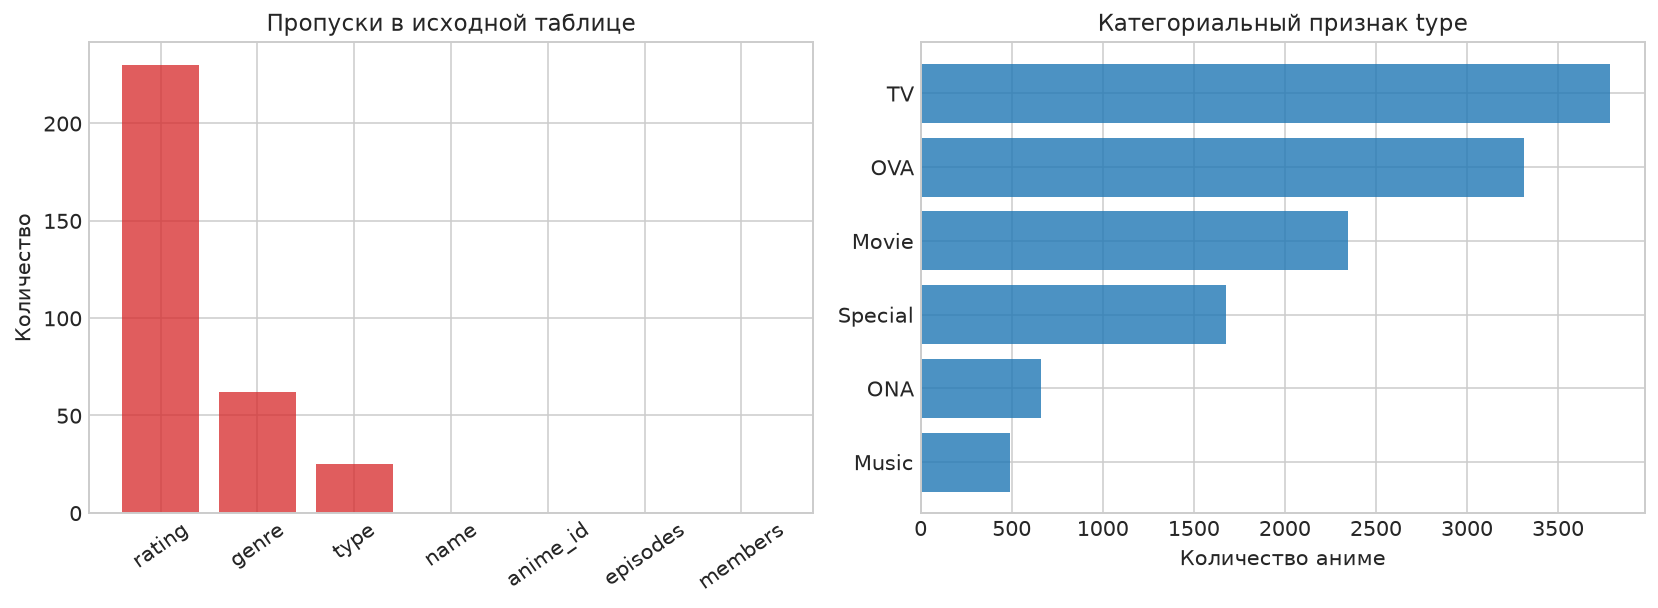

In [3]:
overview_image = overview_plot(anime, OUTPUT_DIR)
display(Image(filename=str(overview_image)))

Для рейтинга отсутствуют 230 значений, для типа — 25. Удаляем строки с пропуском в одном из полей, необходимых для анализа; значения не восстанавливаем, чтобы не создавать искусственные наблюдения. В `members` пропусков нет. После фильтрации одна строка по-прежнему соответствует одному аниме, поэтому повторных измерений одного объекта в выбранной таблице нет.

Рейтинги записаны с точностью до сотых, то есть в данных есть совпадающие значения. Мы проверяем, может ли нормальный закон служить непрерывной вероятностной моделью для округлённого рейтинга, и учитываем дискретизацию при интерпретации результата.

In [4]:
data = anime.dropna(subset=["rating", "type"]).copy()
ratings = data["rating"].to_numpy(dtype=float)

summary = data[["rating", "members"]].describe().T
display(summary)
print(f"После удаления необходимых пропусков осталось {len(data)} аниме.")

,count,mean,std,min,25%,50%,75%,max
rating,12064,6.4739,1.02675,1.67,5.88,6.57,7.18,10
members,12064,18279.5,55275.8,12,221,1539,9485.5,1.01392e+06


После удаления необходимых пропусков осталось 12064 аниме.


## 1. Проверка закона распределения рейтинга

По гистограмме рейтинг выглядит одновершинным и примерно колоколообразным. Проверим нормальную модель с параметрами, оценёнными по выборке:

$$H_0:\;X\sim\mathcal N(\mu,\sigma^2),\qquad
H_1:\;X\text{ не имеет нормального распределения}.$$

Обе гипотезы одинаковы для двух применяемых тестов.

### Собственная реализация критерия Жарка—Бера

Пусть $m_k=n^{-1}\sum_{i=1}^n(X_i-\overline X)^k$, выборочная асимметрия $S=m_3/m_2^{3/2}$, а выборочный коэффициент эксцесса до вычитания трёх $K=m_4/m_2^2$. При нормальности $S=0$ и $K=3$. Статистика

$$JB=\frac n6\left(S^2+\frac{(K-3)^2}{4}\right)
\xrightarrow{d}\chi^2_2.$$

Для уровня $\alpha=0.05$ критическая область имеет вид

$$JB>\chi^2_{2;0.95}=5.991.$$

p-value вычисляется как $\mathbb P(\chi^2_2\ge JB_{obs})$.

Вторым используем омнибус-критерий Д’Агостино—Пирсона $K^2$. Он преобразует выборочные асимметрию и эксцесс к приближённо стандартным нормальным величинам; сумма их квадратов при $H_0$ имеет асимптотическое распределение $\chi^2_2$.

In [5]:
mu_hat = ratings.mean()
sigma_hat = ratings.std(ddof=0)

jb = jarque_bera_manual(ratings, ALPHA)
jb_scipy = stats.jarque_bera(ratings)
np.testing.assert_allclose(jb["statistic"], jb_scipy.statistic, rtol=1e-12)
np.testing.assert_allclose(jb["p_value"], jb_scipy.pvalue, rtol=1e-10)

dagostino = stats.normaltest(ratings)
chi2_critical = stats.chi2.ppf(1 - ALPHA, df=2)
normality_results = pd.DataFrame([
    {
        "критерий": jb["test"],
        "статистика": jb["statistic"],
        "критическое значение": jb["critical"],
        "p-value": jb["p_value"],
        "решение": "отклонить H0" if jb["reject"] else "не отклонять H0",
    },
    {
        "критерий": "Д’Агостино—Пирсона K² (SciPy)",
        "статистика": dagostino.statistic,
        "критическое значение": chi2_critical,
        "p-value": dagostino.pvalue,
        "решение": "отклонить H0" if dagostino.pvalue < ALPHA else "не отклонять H0",
    },
])

print(f"Оценки параметров: μ̂ = {mu_hat:.6f}, σ̂ = {sigma_hat:.6f}")
print(f"Асимметрия S = {jb['skewness']:.6f}; коэффициент K = {jb['kurtosis']:.6f}")
display(normality_results)

Оценки параметров: μ̂ = 6.473902, σ̂ = 1.026704
Асимметрия S = -0.543502; коэффициент K = 3.506822


,критерий,статистика,критическое значение,p-value,решение
0,Жарка—Бера (собственная реализация),723.06,5.99146,9.76146e-158,отклонить H0
1,Д’Агостино—Пирсона K² (SciPy),607.408,5.99146,1.26779e-132,отклонить H0


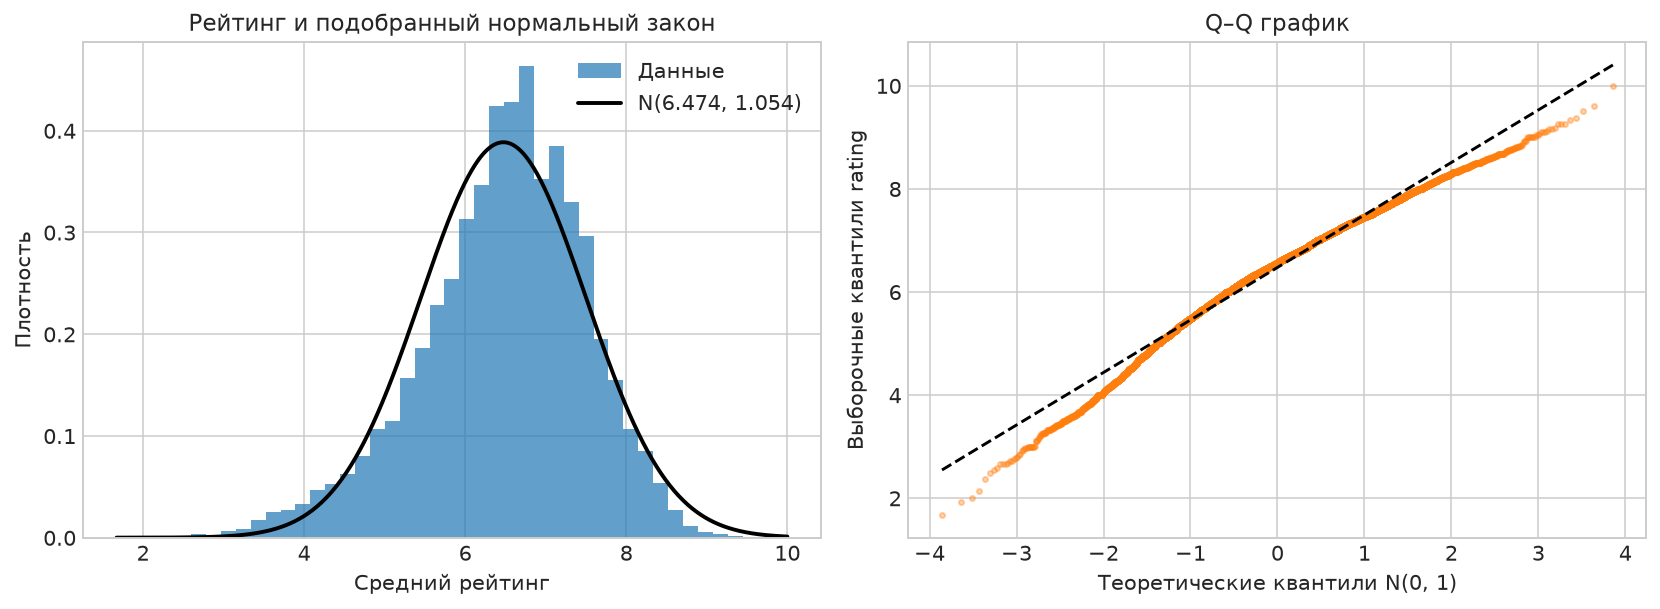

In [6]:
normality_image = normality_plot(ratings, mu_hat, sigma_hat, OUTPUT_DIR)
display(Image(filename=str(normality_image)))

Оба p-value намного меньше $0.05$, поэтому нормальность рейтинга отвергается обоими критериями. Знак асимметрии отрицательный: левый хвост длиннее правого. Q–Q график также показывает систематическое отклонение хвостов от прямой. При таком объёме даже умеренное отклонение обнаруживается с высокой мощностью; округление рейтингов усиливает отличие от строго непрерывной модели, но наблюдаемые асимметрия и эксцесс показывают, что дело не только в округлении.

## 2. Однородность рейтингов TV и Movie

Сравним два наиболее содержательно интерпретируемых типа. Для критерия Колмогорова—Смирнова формулируем:

$$H_0:\;F_{TV}(x)=F_{Movie}(x)\ \text{для всех }x,$$
$$H_1:\;F_{TV}(x)\ne F_{Movie}(x)\ \text{хотя бы для одного }x.$$

Для критерия Манна—Уитни нулевая гипотеза записывается через вероятностное превосходство независимых наблюдений $X_{TV}$ и $X_{Movie}$ с учётом совпадений:

$$H_0:\;\mathbb P(X_{TV}>X_{Movie})+\tfrac12\mathbb P(X_{TV}=X_{Movie})=\tfrac12,$$
$$H_1:\;\mathbb P(X_{TV}>X_{Movie})+\tfrac12\mathbb P(X_{TV}=X_{Movie})\ne\tfrac12.$$

### Собственная реализация двухвыборочного критерия Колмогорова—Смирнова

Статистика измеряет максимальное вертикальное расстояние между эмпирическими функциями распределения:

$$D_{n,m}=\sup_x|F_n(x)-G_m(x)|.$$

При $H_0$ и больших $n,m$ величина $\sqrt{nm/(n+m)}D_{n,m}$ имеет предельное распределение Колмогорова. Критическая область:

$$D_{n,m}>K^{-1}(1-\alpha)\sqrt{\frac{n+m}{nm}},$$

где $K$ — функция распределения предельного закона. p-value берётся из его функции выживания.

Второй критерий — двусторонний Манна—Уитни. Он основан на рангах объединённой выборки и чувствителен прежде всего к систематическому сдвигу распределений. Его использование вместе с KS позволяет отличить общий факт неоднородности от сдвига центрального уровня.

In [7]:
tv = data.loc[data["type"] == "TV", "rating"].to_numpy()
movie = data.loc[data["type"] == "Movie", "rating"].to_numpy()

group_summary = pd.DataFrame({
    "n": [tv.size, movie.size],
    "mean": [tv.mean(), movie.mean()],
    "median": [np.median(tv), np.median(movie)],
    "std": [tv.std(ddof=1), movie.std(ddof=1)],
}, index=["TV", "Movie"])
display(group_summary)

ks = ks_2samp_manual(tv, movie, ALPHA)
ks_scipy = stats.ks_2samp(tv, movie, alternative="two-sided", method="asymp")
np.testing.assert_allclose(ks["statistic"], ks_scipy.statistic, rtol=1e-12)

mann_whitney = stats.mannwhitneyu(tv, movie, alternative="two-sided", method="asymptotic")
homogeneity_results = pd.DataFrame([
    {
        "критерий": ks["test"],
        "статистика": ks["statistic"],
        "критическое значение": ks["critical"],
        "p-value": ks["p_value"],
        "решение": "отклонить H0" if ks["reject"] else "не отклонять H0",
    },
    {
        "критерий": "Манна—Уитни U (SciPy)",
        "статистика": mann_whitney.statistic,
        "критическое значение": np.nan,
        "p-value": mann_whitney.pvalue,
        "решение": "отклонить H0" if mann_whitney.pvalue < ALPHA else "не отклонять H0",
    },
])
display(homogeneity_results)
print(f"Проверка KS по SciPy: D = {ks_scipy.statistic:.6f}, p-value = {ks_scipy.pvalue:.3e}")

,n,mean,median,std
TV,3671,6.9023,6.94,0.863526
Movie,2297,6.31806,6.47,1.21199


,критерий,статистика,критическое значение,p-value,решение
0,Колмогорова—Смирнова (собственная реализация),0.251477,0.0361304,4.89082e-78,отклонить H0
1,Манна—Уитни U (SciPy),5.39704e+06,NaN,2.7709e-74,отклонить H0


Проверка KS по SciPy: D = 0.251477, p-value = 3.118e-79


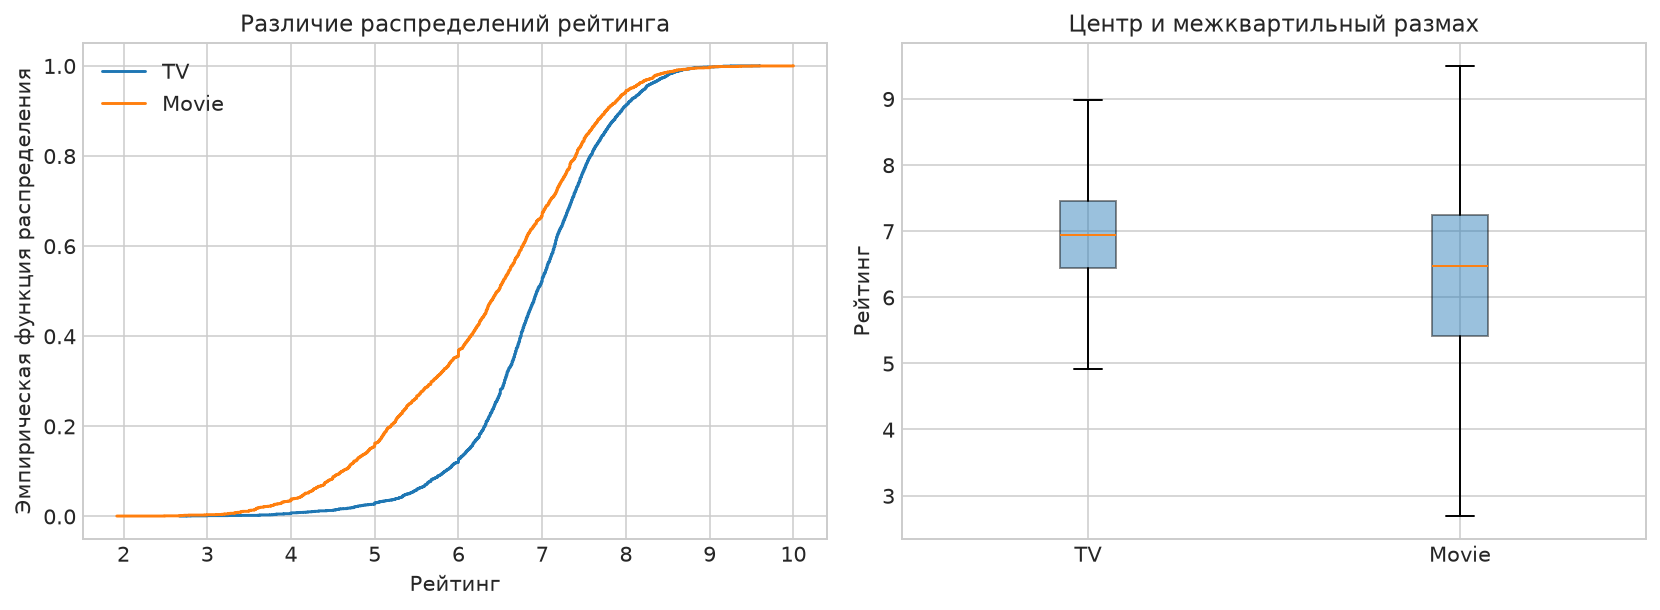

In [8]:
homogeneity_image = homogeneity_plot(tv, movie, OUTPUT_DIR)
display(Image(filename=str(homogeneity_image)))

Статистика KS заметно превышает критическое значение, а p-value обоих критериев намного меньше $0.05$. Следовательно, распределения рейтингов TV и Movie неоднородны. Медиана TV выше медианы Movie примерно на $0.47$, а среднее — примерно на $0.58$. Критерий Манна—Уитни подтверждает, что различие связано не только с локальным расхождением форм распределений, но и с их систематическим сдвигом.

У рейтингов есть совпадения из-за округления. Для Манна—Уитни SciPy применяет асимптотическую поправку на совпадающие ранги; для KS используется асимптотическая версия, поэтому результат трактуется как крупновыборочный.

## 3. Связь рейтинга с популярностью

Распределение `members` сильно скошено вправо, поэтому для линейной зависимости используем $Z=\log_{10}(members+1)$. Логарифм монотонен и не меняет порядок объектов.

Для перестановочного теста Пирсона:

$$H_0:\;Z\ \text{и }rating\ \text{независимы (и потому }\rho=0\text{)},$$
$$H_1:\;\rho\ne0.$$

Для критерия Спирмена:

$$H_0:\;\rho_s=0,\qquad H_1:\;\rho_s\ne0,$$

где $\rho_s$ — ранговая корреляция, обнаруживающая монотонную связь.

### Собственный перестановочный тест

Наблюдаемая статистика — коэффициент корреляции Пирсона

$$r=\frac{\sum_i(Z_i-\overline Z)(R_i-\overline R)}
{\sqrt{\sum_i(Z_i-\overline Z)^2\sum_i(R_i-\overline R)^2}}.$$

При $H_0$ рейтинги можно переставлять относительно популярности. Строим $B=5000$ перестановок, критическим значением считаем эмпирический квантиль уровня $0.95$ распределения $|r^*|$. Критическая область имеет вид $|r|>q^*_{0.95}$. Чтобы p-value не было нулевым при конечном $B$, используем поправку

$$p=\frac{1+\#\{|r^*|\ge|r_{obs}|\}}{B+1}.$$

In [9]:
members = data["members"].to_numpy(dtype=float)
log_members = np.log10(members + 1)

pearson_perm = pearson_permutation_test(
    log_members,
    ratings,
    permutations=PERMUTATIONS,
    alpha=ALPHA,
    seed=SEED,
)
pearson_scipy = stats.pearsonr(log_members, ratings)
np.testing.assert_allclose(pearson_perm["statistic"], pearson_scipy.statistic, rtol=1e-12)

spearman = stats.spearmanr(members, ratings)
association_results = pd.DataFrame([
    {
        "критерий": pearson_perm["test"],
        "коэффициент": pearson_perm["statistic"],
        "критическое |значение|": pearson_perm["critical"],
        "p-value": pearson_perm["p_value"],
        "решение": "отклонить H0" if pearson_perm["reject"] else "не отклонять H0",
    },
    {
        "критерий": "Спирмена (SciPy)",
        "коэффициент": spearman.statistic,
        "критическое |значение|": np.nan,
        "p-value": spearman.pvalue,
        "решение": "отклонить H0" if spearman.pvalue < ALPHA else "не отклонять H0",
    },
])
display(association_results)
print(
    "Минимально различимый перестановочный p-value: "
    f"1/(B+1) = {1/(PERMUTATIONS+1):.6g}"
)

,критерий,коэффициент,критическое |значение|,p-value,решение
0,"Пирсон, перестановочный (собственная реализация)",0.648254,0.0175507,0.00019996,отклонить H0
1,Спирмена (SciPy),0.666345,NaN,0,отклонить H0


Минимально различимый перестановочный p-value: 1/(B+1) = 0.00019996


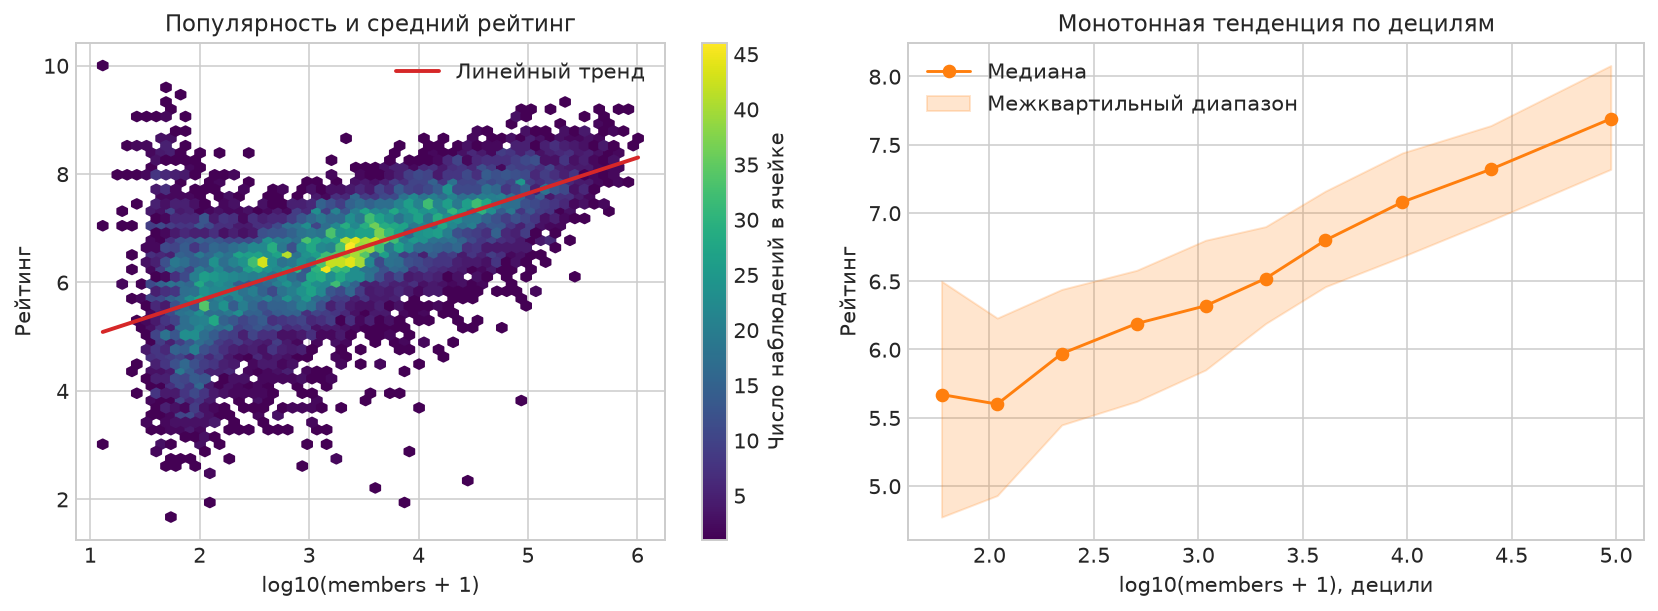

In [10]:
association_image = association_plot(ratings, members, OUTPUT_DIR)
display(Image(filename=str(association_image)))

Наблюдаемый $r\approx0.648$ намного больше перестановочного критического значения по модулю; ни одна из 5000 перестановок не дала столь сильной корреляции, поэтому скорректированный p-value равен $1/5001\approx0.0002$. Коэффициент Спирмена $\rho_s\approx0.666$ также указывает на сильную положительную монотонную связь. Обе нулевые гипотезы отвергаются: более популярные аниме в этом наборе в среднем имеют более высокий рейтинг.

Это наблюдательная ассоциация, а не причинный эффект. По данным нельзя заключить, что рост аудитории сам по себе повышает рейтинг: на обе величины могут влиять качество, возраст тайтла, жанр, маркетинг и механизм попадания в MyAnimeList.

## Множественные проверки

В работе проведено шесть формальных тестов. Если контролировать семейную вероятность ошибки первого рода простой поправкой Бонферрони, порог равен

$$\alpha_{family}/6=0.05/6\approx0.00833.$$

Все полученные p-value меньше этого порога, включая конечное перестановочное значение $1/5001$, поэтому выводы не меняются.

## Выводы

1. Для среднего рейтинга была предложена нормальная модель $\mathcal N(6.474,1.027^2)$. Собственная реализация Жарка—Бера и критерий Д’Агостино—Пирсона отвергли нормальность: распределение имеет отрицательную асимметрию и отличный от нормального эксцесс.
2. Собственная реализация двухвыборочного критерия Колмогорова—Смирнова и критерий Манна—Уитни отвергли однородность рейтингов TV и Movie. У TV центральный уровень рейтинга выше.
3. Собственный перестановочный тест Пирсона для `log10(members + 1)` и ранговый критерий Спирмена обнаружили сильную положительную связь популярности с рейтингом ($r\approx0.648$, $\rho_s\approx0.666$).
4. Все самостоятельно реализованные тесты явно возвращают наблюдаемую статистику, границу критической области и p-value; их статистики дополнительно сверены с реализациями SciPy.
5. Статистическая значимость не доказывает практическую причинность. Результаты описывают именно данный срез MyAnimeList и зависят от механизма формирования и округления исходных показателей.